# 01 — Fluorescent-bead registration and plane spacing

**Purpose.** Calibrate the 8-plane prism from a fluorescent-bead stage scan: the 8 panel windows and orientations on the two
cameras, the plane offsets Δ_p and the inter-plane distance, the affine map of every plane onto a reference plane, and the
relative transmission of the 8 channels.

**SI references** (Descloux et al. 2018): §6.1 (magnification, pixel ≈ 111 nm), §6.2 (prism: 4 images per camera, interlaced,
design inter-plane distance d/(2n)/M_l²; measured 347 ± 11 nm from beads scanned in 200 nm steps), §6.4 and Fig. S16 (affine
transformation + bilinear interpolation fitted on a bead scan; the same scan corrects the transmission of the 8 channels),
§8.3 (bead sample).

**Input.** A fluorescent-bead z-stack (stage scan, 200 nm steps), `.dat` + `.info` or a TIFF acquisition folder. Any
preparation works: the sample index `N_SAMPLE` is a parameter.

**Output** (`<stem>_01_registration/`): `calibration.json` (contract in `docs/DESIGN.md`), `beads.npz`, figures `NN_*.png`.

**Paper method vs. implementation.** The SI gives the measurement (bead z-scan), the quantities (Δ, spacing, affine,
transmission) and the warp (affine + bilinear). It does not say how panels, beads, focus or bead positions are found: those
procedures are implementation choices and all their thresholds are declared below as `heuristic`.

**Extensions (not in the paper)**, reported and switched off unless stated:
* §5 focal-plane tilt fit (in-panel focus gradients); its Δ is exported next to the paper Δ and only replaces it if
  `USE_TILT_CORRECTED_DELTA = True`;
* §6 common lateral-slope (stage-drift) correction of the bead positions, `CORRECT_COMMON_SLOPE = False`;
* §4 camera-B comb offset, a diagnostic that tests the camera-B frame pairing taken from the instrument file;
* §7 2nd-order polynomial comparison (diagnostic only);
* Δ in sample space: Δ_stage × n_sample / n_immersion (paraxial). Both stage- and sample-space Δ are exported.

In [1]:
import json, textwrap, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage

from mpqpi import io, geometry, registration as R
from mpqpi.config import Instrument, data_path, output_dir
from mpqpi.params import REG
from mpqpi.provenance import write_json

warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*(All-NaN|Mean of empty|empty slice|Degrees of freedom).*")
REG.clear()
INST = Instrument()

# ---------------------------------------------------------------- user: data, objective, sample
DATA_FILE = data_path("/Users/quentingresil/Library/CloudStorage/OneDrive-epfl.ch/POSTDOC/data/260928_registration/20260928_134359_GPSBeads_Stock_1-10_Agarpse_2_488nm_zstack.dat")
REG.declare("data_file", str(DATA_FILE), "user", "bead z-stack (.dat or TIFF folder), relative to data_root")
OBJECTIVE = REG.declare("objective", "60x_water", "user", "objective used for the bead scan (key in the instrument file)")
N_SAMPLE = REG.declare("n_sample", 1.33, "user", "refractive index of the medium around the beads",
                       note="set it for your preparation (water / agarose ≈ 1.33; PS-Speck mounting medium: check its index)")
PANEL_OVERRIDE = REG.declare("panel_override", None, "user", "None = detect; or {'A': [(top, left, h, w)]*4, 'B': [...]} raw coords")
STREAM_B_ORIENTATION = REG.declare("stream_b_orientation", None, "user", "None = measure (§2); or 'none', 'lr', 'ud', 'lrud'")

# ---------------------------------------------------------------- instrument, paper, derived
N_IMM = INST.value(f"objectives.{OBJECTIVE}.n_immersion", "n_immersion")
PIXEL_UM = INST.pixel_um(OBJECTIVE)
OFFSET = INST.value("cameras.offset_counts")
B_SHIFT = INST.value("cameras.stream_b_z_shift_steps")
N_PANELS = REG.declare("n_panels_per_camera", 4, "paper", "SI §6.2: a row of four images per camera")
M_L = REG.declare("lateral_magnification", INST.value("cameras.pixel_pitch_um") / PIXEL_UM, "derived", "pixel pitch / pixel_um (SI §6.1)")
DZ_DESIGN = REG.declare("plane_spacing_design_um",
                        R.design_plane_spacing_um(INST.value("detection.prism_d_mm"), INST.value("detection.prism_n"), M_L), "derived",
                        "SI §6.2: δz = d / (2n) / M_a, M_a = M_l² (object space)", "µm")
DZ_PAPER = INST.value("detection.plane_spacing_paper_um")
DZ_PAPER_SD = REG.declare("plane_spacing_paper_sd_um", 0.011, "paper", "SI §6.2: ± 11 nm, SD over 8 beads (60x)", "µm")
AXIAL_SCALE = REG.declare("axial_scale", R.axial_scale(N_SAMPLE, N_IMM), "derived",
                          "Δ_sample = Δ_stage · n_sample / n_immersion (paraxial focal shift; 1 when index-matched)",
                          note="paraxial: a high-NA focal-shift model gives a different factor under index mismatch")


def H(name, value, why, unit=""):
    return REG.declare(name, value, "heuristic", why, unit)


u = lambda um, **k: R.px(um, PIXEL_UM, **k)            # physical size -> pixels at this objective

# ---------------------------------------------------------------- heuristics: panels (camera-plane sizes, objective independent)
PANEL_LEVEL = H("panel_level", 0.5, "illuminated = above half of the percentile range (half maximum)")
PANEL_SMOOTH_PX = H("panel_smooth_px", 3, "smoothing of row/column profiles (camera px)", "px")
PANEL_PERCENTILES = H("panel_percentiles", [2, 98], "background / plateau levels robust to hot pixels and beads")
PANEL_MIN_LIT_PX = H("panel_min_lit_px", 20, "ignore illuminated runs narrower than this", "px")
PANEL_GAP_SEARCH = H("panel_gap_search", 0.2, "search the gap within ± this fraction of the pitch around the equal-pitch position")
PANEL_MIN_GAP_DEPTH = H("panel_min_gap_depth", 0.15, "a gap must drop ≥ 15 % from plateau to background, else give the windows")
PANEL_MARGIN_PX = H("panel_margin_px", 10, "trim the vignetted field-stop edge (camera px)", "px")
# ---------------------------------------------------------------- heuristics: projections, orientation, beads
SMOOTH_Z_UM = H("proj_smooth_z_um", 0.2, "z smoothing (stage) before the max projection: one step", "µm")
SMOOTH_XY_UM = H("proj_smooth_xy_um", 0.111, "xy smoothing before the max projection (≈ 1 px at 60x)", "µm")
DOG_UM = H("dog_sigmas_um", [0.055, 0.44], "difference of Gaussians: keeps bead-sized features (PSF σ ≈ 0.1 µm)", "µm")
TUKEY = H("tukey_alpha", 0.25, "apodisation of the phase correlation")
ORIENT_CANDIDATES = H("orient_candidates", ["none", "lr", "ud", "lrud"], "flips only (a 90° rotation would show in the affine)")
MATCH_REF = H("match_reference_panel", "A0", "bead list and coarse shifts from this panel (beads absent there are not used)")
DETECT_SIGMA = H("detect_sigma", 6.0, "bead detection threshold on the projection, robust σ")
PEAK_UM = H("peak_window_um", 0.5, "local-maximum window (≈ 5 px at 60x)", "µm")
ROI_HALF_UM = H("roi_half_um", 0.67, "bead ROI half-width for focus metric and 2D fits (13 px at 60x)", "µm")
CORE_HALF_UM = H("core_half_um", 0.111, "focus-metric core half-width (3 × 3 px at 60x)", "µm")
ISOLATION_UM = H("isolation_um", 1.55, "drop beads with a neighbour closer than this (overlapping defocused images)", "µm")
MATCH_RADII_UM = H("match_radii_um", [0.44, 0.33, 0.22, 0.22], "mutual-NN radii: coarse shift, then affine refinements", "µm")
MIN_PANELS = H("min_panels_per_bead", 6, "keep beads matched in ≥ this many of the 8 panels")
# ---------------------------------------------------------------- heuristics: focus and Δ
FOCUS_HALF_UM = H("focus_half_window_um", {"60x_water": 1.2, "100x_oil": 0.8}[OBJECTIVE],
                  "Gaussian focus fit within ± this stage range around the maximum (≈ axial PSF FWHM; objective-specific)", "µm")
FOCUS_WIDTH_UM = H("focus_width_bounds_um", [0.05, 2.0], "accept focus fits with σ_z in this range (stage)", "µm")
FOCUS_SIGMA0_UM = H("focus_sigma0_um", 0.4, "initial σ_z of the focus fit (start value only)", "µm")
FOCUS_MAX_SHIFT = H("focus_max_shift_steps", 2, "reject fits whose centre moved more than this from the maximum", "steps")
FOCUS_EDGE = H("focus_edge_frames", 2, "reject beads whose maximum is this close to the stack ends", "frames")
MIN_SNR = H("min_axial_snr", 5.0, "reject focus fits below amplitude / residual SD")
AXIAL_ITER = H("axial_n_iter", 30, "alternating-median iterations of z_focus = z_b + Δ_p (main fit and bootstrap)")
AXIAL_CLIP = H("axial_clip_sigma", 4.0, "clip focus positions with |residual| > this × robust σ (main fit and bootstrap)")
N_BOOT = H("n_boot", 200, "bootstrap resamples over beads (Δ, spacing, transmission SDs)")
SEED = H("seed", 0, "bootstrap random seed")
USE_TILT_DELTA = H("use_tilt_corrected_delta", False, "extension switch: export the tilt-fit Δ as delta_z_um (False = paper Δ)")
# ---------------------------------------------------------------- heuristics: positions and registration
LATERAL_UM = H("lateral_window_um", {"60x_water": 1.0, "100x_oil": 0.6}[OBJECTIVE],
               "frames within ± this (stage) of focus are localised for x(z), y(z) (objective-specific)", "µm")
GAUSS_SIGMA0_UM = H("gauss_sigma0_um", 0.17, "initial PSF σ of the 2D Gaussian localisation (start value)", "µm")
LM_ITER = H("lm_n_iter", 40, "Levenberg–Marquardt iterations of the 2D Gaussian fit")
LATERAL_MIN_FRAMES = H("lateral_min_frames", 4, "minimum localised frames for the x(z), y(z) line")
CORRECT_COMMON_SLOPE = H("correct_common_slope", False, "extension switch (§6): refer positions to one stage z with the common slope")
REFERENCE_PLANE = H("reference_plane", "P5", "middle plane (P4/P5 equidistant for 8 planes); the SI names no reference")
AFFINE_CLIP = H("affine_clip_sigma", 3.0, "clip beads with residual norm > this × σ, σ = median|r| / √(2 ln 2)")
AFFINE_ITER = H("affine_n_iter", 5, "clipping iterations of the affine fit")
# ---------------------------------------------------------------- heuristics: transmission
TRANS_RADIUS_UM = H("transmission_radius_um", 2.0, "photometry disc: must contain the defocused images of the outer planes (§8 check)", "µm")
TRANS_BG_UM = H("transmission_bg_width_um", 0.5, "background annulus width", "µm")
TRANS_HALF_UM = H("transmission_half_window_um", 0.2, "frames within ± this (stage) of the bead's mean focus", "µm")
TRANS_RADII_CHECK_UM = H("transmission_radii_check_um", [0.75, 1.0, 1.5, 2.0, 2.5, 3.0], "convergence check of the disc radius", "µm")
# ---------------------------------------------------------------- heuristics: QC only (warnings / overlay metric)
NCC_THR = H("ncc_threshold_sigma", 3.0, "QC: bead pixels for the overlay NCC")
NCC_BORDER_UM = H("ncc_border_um", 2.2, "QC: border excluded from the NCC", "µm")
WARN_MIN_BEADS = H("warn_min_beads", 30, "QC: warn below this many beads")
WARN_COMB_TOL = H("warn_comb_tol_delta", 0.25, "QC: warn if the camera-B comb offset is further than this from ±1 δ")
WARN_POLY2 = H("warn_poly2_gain", 0.8, "QC: warn if poly-2 LOO error < this × affine LOO error")

OUT = output_dir(DATA_FILE, "01_registration")
CAM_COLOR = {"A": "#3a78b5", "B": "#e07b28"}
WARNINGS = []


def warn(msg):
    WARNINGS.append(msg); print("WARNING:", msg)


def save(fig, name):
    fig.savefig(OUT / name, dpi=200); plt.show()


REG.banner()
print("OUT:", OUT)

HEURISTIC (49)  <- choices made in the code, review these
  cameras.stream_b_z_shift_steps =              0        frame 2k+1 recorded at the same stage z as frame 2k  [unverified; notebook 01 reports the camera comb offset that tests it]
  panel_level                  =            0.5        illuminated = above half of the percentile range (half maximum)
  panel_smooth_px              =              3 px     smoothing of row/column profiles (camera px)
  panel_percentiles            =        [2, 98]        background / plateau levels robust to hot pixels and beads
  panel_min_lit_px             =             20 px     ignore illuminated runs narrower than this
  panel_gap_search             =            0.2        search the gap within ± this fraction of the pitch around the equal-pitch position
  panel_min_gap_depth          =           0.15        a gap must drop ≥ 15 % from plateau to background, else give the windows
  panel_margin_px              =             10 px     trim the 

## 1. Raw data and panel windows
Each camera stream holds four panels side by side (SI §6.2). Windows come from the z-mean image: the illuminated band is split
in four equal pitches and the darkest column near each expected boundary is the gap. Windows are trimmed by `panel_margin_px`
and cut to a common size. **Check:** boxes inside the lit areas, red lines in the dips of the column profile.

dat: 60 frames per camera of (2048, 2048); step 250 nm (SI: 200 nm); camera-B pairing shift 0 step(s) (instrument file)
panels 880 × 392 px; gap depths A [1.04, 0.7, 0.9], B [0.71, 0.68, 1.02]


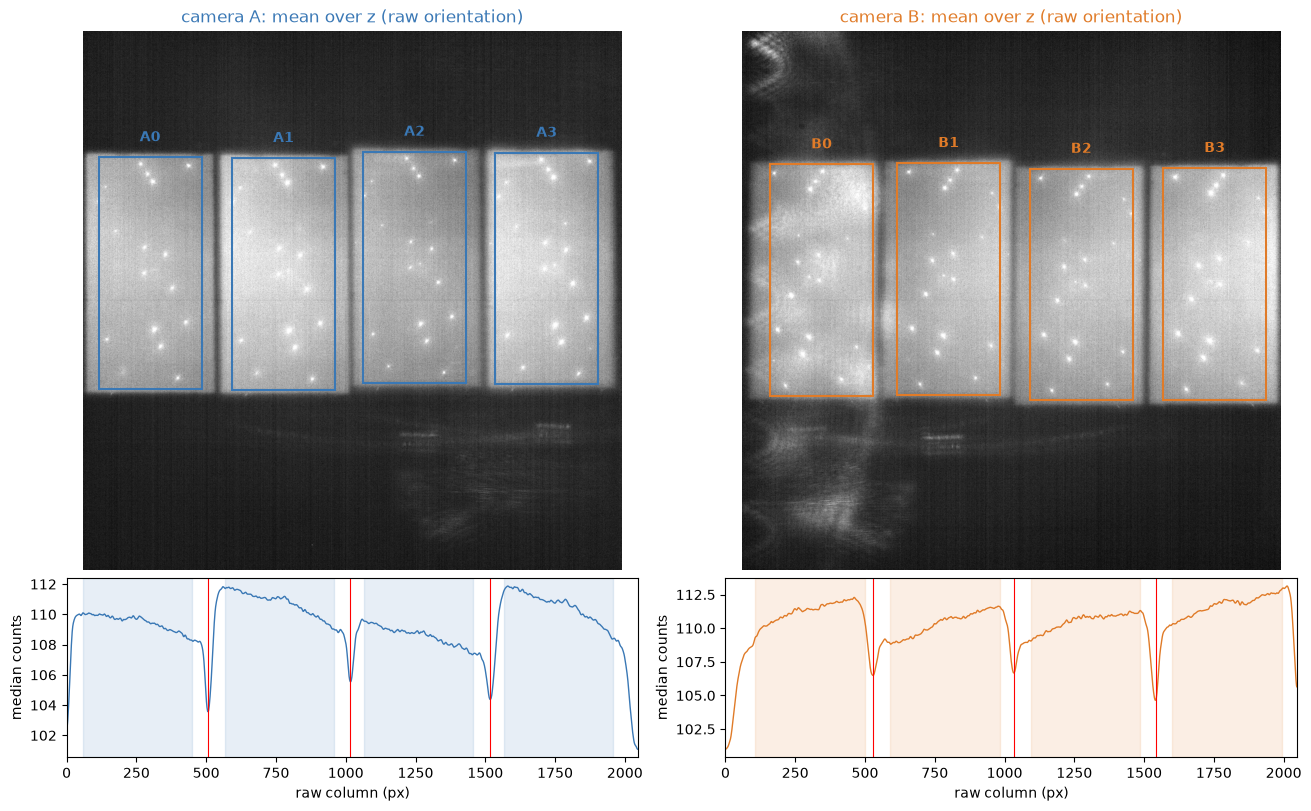

In [2]:
acq = io.load(DATA_FILE, INST)
if acq.z_um["A"] is None:
    raise RuntimeError("no z information: this is not a z-stack")
Z = acq.z_um
STEP = acq.step_um()
print(f"{acq.fmt}: {acq.n_frames} frames per camera of {acq.streams['A'].shape[1:]}; step {1e3 * STEP:.0f} nm "
      f"(SI: 200 nm); camera-B pairing shift {B_SHIFT} step(s) (instrument file)")
mean_img = {s: R.mean_image(acq.streams[s]) for s in "AB"}
panel_diag, detected = {}, {}
for s in "AB":
    if PANEL_OVERRIDE is not None:
        detected[s] = [tuple(w) for w in PANEL_OVERRIDE[s]]; continue
    detected[s], panel_diag[s] = R.detect_panels(mean_img[s], N_PANELS, PANEL_LEVEL, PANEL_SMOOTH_PX, PANEL_PERCENTILES,
                                                 PANEL_MIN_LIT_PX, PANEL_GAP_SEARCH, PANEL_MIN_GAP_DEPTH)
panels = R.common_windows(detected, PANEL_MARGIN_PX)
IDS = [q["id"] for q in panels]; P = len(panels)
HC, WC = panels[0]["window_raw"]["height"], panels[0]["window_raw"]["width"]
print(f"panels {HC} × {WC} px; gap depths " + ", ".join(f"{s} {np.round(d['depths'], 2).tolist()}" for s, d in panel_diag.items()))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", gridspec_kw={"height_ratios": [3, 1]})
for c, s in enumerate("AB"):
    ax = axes[0, c]; lo, hi = np.percentile(mean_img[s], [1, 99.5])
    ax.imshow(mean_img[s], cmap="gray", vmin=lo, vmax=hi)
    for q in panels:
        if q["stream"] == s:
            w = q["window_raw"]
            ax.add_patch(Rectangle((w["left"], w["top"]), w["width"], w["height"], fill=False, ec=CAM_COLOR[s], lw=1.5))
            ax.text(w["left"] + w["width"] / 2, w["top"] - 0.03 * mean_img[s].shape[0], q["id"], color=CAM_COLOR[s], weight="bold", ha="center")
    ax.set_title(f"camera {s}: mean over z (raw orientation)", color=CAM_COLOR[s]); ax.axis("off")
    ax = axes[1, c]
    if s in panel_diag:
        ax.plot(panel_diag[s]["col_profile"], color=CAM_COLOR[s], lw=1)
        for g in panel_diag[s]["gaps"]:
            ax.axvline(g, color="r", lw=0.8)
    for q in panels:
        if q["stream"] == s:
            ax.axvspan(q["window_raw"]["left"], q["window_raw"]["left"] + WC, color=CAM_COLOR[s], alpha=0.12)
    ax.set(xlim=(0, mean_img[s].shape[1]), xlabel="raw column (px)", ylabel="median counts")
save(fig, "01_panels.png")

## 2. Panel orientation
All panels see the same beads during the scan, so their bead projections must coincide after the right flip. Each panel is
phase-correlated with the matching-reference panel in the four orientations; camera A defines the frame (`none`), camera B gets
the orientation with the largest summed SNR. **Check:** one winning column for B; A panels prefer `none` (control).

camera B orientation 'lr' (winner / runner-up ≥ 2.4)


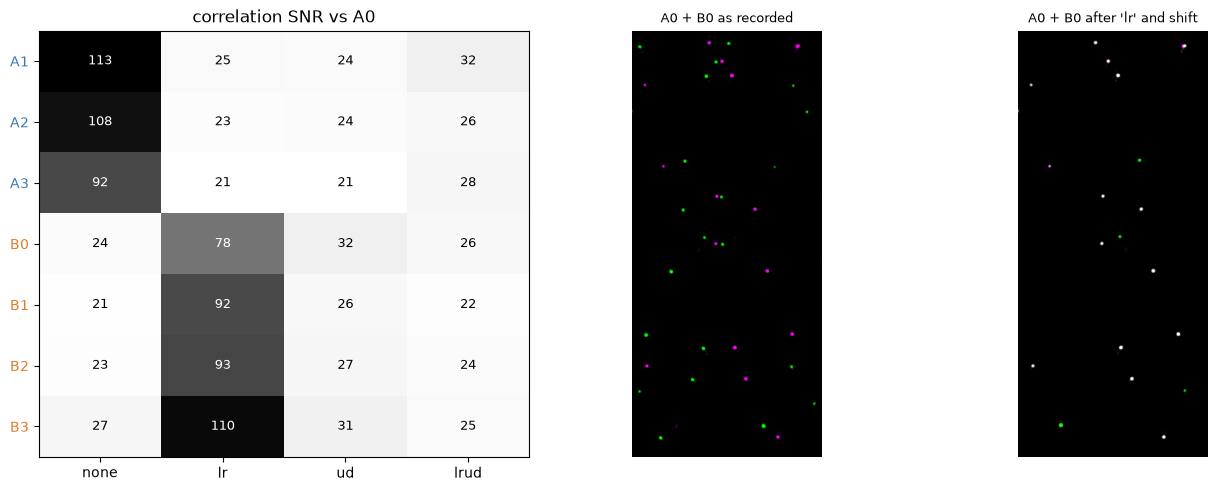

In [3]:
raw = {q["id"]: io.to_signal(geometry.panel(acq.streams, {**q, "orientation": "none"}), OFFSET) for q in panels}
SM = (SMOOTH_Z_UM / STEP, SMOOTH_XY_UM / PIXEL_UM, SMOOTH_XY_UM / PIXEL_UM); DOGPX = tuple(d / PIXEL_UM for d in DOG_UM)
mip_raw = {k: R.bead_projection(v, SM, DOGPX) for k, v in raw.items()}
scores = R.orientation_scores(mip_raw, MATCH_REF, ORIENT_CANDIDATES, TUKEY)
orient_B, winners, ratio = R.choose_orientation(scores, "B")
if STREAM_B_ORIENTATION is not None:
    orient_B = STREAM_B_ORIENTATION
if len(set(winners.values())) > 1:
    warn(f"B panels disagree on orientation: {winners}")
for k, v in scores.items():
    if k.startswith("A") and max(v, key=v.get) != "none":
        warn(f"orientation control failed: {k} prefers {max(v, key=v.get)}")
if ratio < 2:
    warn(f"orientation decision is weak (winner / runner-up = {ratio:.1f})")
for q in panels:
    q["orientation"] = "none" if q["stream"] == "A" else orient_B
stacks = [geometry.ORIENT[q["orientation"]](raw[q["id"]]) for q in panels]
mips = {q["id"]: geometry.ORIENT[q["orientation"]](mip_raw[q["id"]]) for q in panels}
shifts = {k: R.phase_correlation(mips[MATCH_REF], mips[k], TUKEY)[0] for k in IDS}
print(f"camera B orientation '{orient_B}' (winner / runner-up ≥ {ratio:.1f})")


def rz(img):
    return (img - np.nanmedian(img)) / R.robust_sigma(img)


def overlay(ref, mov, blur=1.0):
    """magenta = reference, green = other, white = both."""
    def nrm(a):
        a = ndimage.gaussian_filter(np.clip(np.nan_to_num(rz(a)) - NCC_THR, 0, None), blur)
        return a / (np.percentile(a, 99.9) + 1e-9)
    r, g = nrm(ref), nrm(mov)
    return np.clip(np.dstack([r, g, r]), 0, 1)


others = [k for k in IDS if k != MATCH_REF]
tab = np.array([[scores[k][o] for o in ORIENT_CANDIDATES] for k in others])
b0 = next(k for k in IDS if k.startswith("B"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]; ax.imshow(tab, cmap="Greys", aspect="auto")
for i in range(len(others)):
    for k in range(len(ORIENT_CANDIDATES)):
        ax.text(k, i, f"{tab[i, k]:.0f}", ha="center", va="center", fontsize=9, color="w" if tab[i, k] > 0.5 * tab.max() else "k")
ax.set(xticks=range(len(ORIENT_CANDIDATES)), xticklabels=ORIENT_CANDIDATES, yticks=range(len(others)), yticklabels=others,
       title=f"correlation SNR vs {MATCH_REF}")
for t in ax.get_yticklabels():
    t.set_color(CAM_COLOR[t.get_text()[0]])
axes[1].imshow(overlay(mips[MATCH_REF], mip_raw[b0])); axes[1].set_title(f"{MATCH_REF} + {b0} as recorded", fontsize=9)
axes[2].imshow(overlay(mips[MATCH_REF], ndimage.shift(mips[b0], -shifts[b0][::-1], order=1)))
axes[2].set_title(f"{MATCH_REF} + {b0} after '{orient_B}' and shift", fontsize=9)
for ax in axes[1:]:
    ax.axis("off")
save(fig, "02_orientation.png")

## 3. Beads
Beads are detected on each projection, beads of the matching-reference panel with a close neighbour are dropped, the others are
matched in every panel (coarse shift → affine prediction → mutual nearest neighbours).

A0: 48 detections, 29 isolated, 11 beads matched in ≥ 6 panels


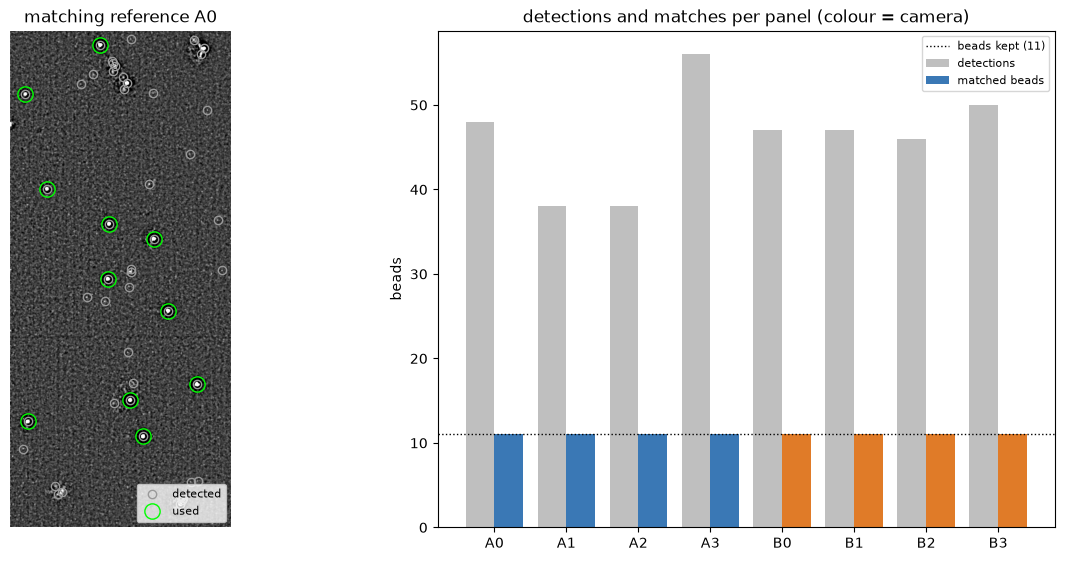

In [4]:
ROI = u(ROI_HALF_UM); BORDER = ROI + 3
det = {k: R.detect_beads(mips[k], DETECT_SIGMA, u(PEAK_UM, odd=True, minimum=3), BORDER) for k in IDS}
pos_mip, ref0, iso = R.match_beads(det, MATCH_REF, shifts, u(ISOLATION_UM), [u(r) for r in MATCH_RADII_UM], MIN_PANELS)
NB = len(pos_mip)
print(f"{MATCH_REF}: {len(ref0)} detections, {iso.sum()} isolated, {NB} beads matched in ≥ {MIN_PANELS} panels")
if NB < WARN_MIN_BEADS:
    warn(f"only {NB} beads: affine and axial statistics will be weak")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained", gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]; jr = IDS.index(MATCH_REF)
ax.imshow(rz(mips[MATCH_REF]), cmap="gray", vmin=-3, vmax=1.5 * DETECT_SIGMA)
ax.plot(ref0[:, 0], ref0[:, 1], "o", mfc="none", mec="0.6", ms=6, label="detected")
ax.plot(pos_mip[:, jr, 0], pos_mip[:, jr, 1], "o", mfc="none", mec="lime", ms=11, label="used")
ax.legend(loc="lower right", fontsize=8); ax.set_title(f"matching reference {MATCH_REF}"); ax.axis("off")
ax = axes[1]; xs = np.arange(P)
ax.bar(xs - 0.2, [len(det[k]) for k in IDS], 0.4, color="0.75", label="detections")
ax.bar(xs + 0.2, np.isfinite(pos_mip[..., 0]).sum(0), 0.4, color=[CAM_COLOR[k[0]] for k in IDS], label="matched beads")
ax.axhline(NB, color="k", ls=":", lw=1, label=f"beads kept ({NB})")
ax.set(xticks=xs, xticklabels=IDS, ylabel="beads", title="detections and matches per panel (colour = camera)"); ax.legend(fontsize=8)
save(fig, "03_beads.png")

## 4. Focus, plane offsets Δ and plane spacing (SI §6.2)
For every bead and panel the on-axis signal (core minus local background) is fitted with a Gaussian + constant in stage z; its
centre is the stage z at which the bead is in focus in that plane. All beads together fit
$z_\text{focus}[b,p] = z_b + \Delta_p$ (alternating medians, one `axial_clip_sigma` clip, bootstrap over beads with the same
estimator). Planes are named P1…P8 by ascending Δ (stage z). Spacing is reported two ways: per gap from the global Δ, and as
mean ± SD over beads of each bead's (z_P8 − z_P1)/7 — the SI §6.2 statistic (347 ± 11 nm, 8 beads, 60x).

In [5]:
z_focus = np.full((NB, P), np.nan); snr = np.full((NB, P), np.nan); curves = {}
for j, q in enumerate(panels):
    ok = np.flatnonzero(np.isfinite(pos_mip[:, j, 0]))
    sig = R.focus_signal(stacks[j], pos_mip[ok, j], ROI, u(CORE_HALF_UM))
    curves[j] = dict(zip(ok, sig))
    for b, c in zip(ok, sig):
        z0, _, s_ = R.fit_focus(Z[q["stream"]], c, FOCUS_HALF_UM, FOCUS_WIDTH_UM, FOCUS_SIGMA0_UM, FOCUS_MAX_SHIFT, FOCUS_EDGE)
        z_focus[b, j], snr[b, j] = z0, s_
z_focus[~(snr >= MIN_SNR)] = np.nan
delta, z_bead, zf = R.plane_offsets(z_focus, AXIAL_ITER, AXIAL_CLIP)
boot = R.bootstrap_offsets(z_focus, N_BOOT, SEED, AXIAL_ITER, AXIAL_CLIP)
resid = zf - z_bead[:, None] - delta
order = np.argsort(delta)
NAME = {j: f"P{r + 1}" for r, j in enumerate(order)}
for j, q in enumerate(panels):
    q["plane"] = NAME[j]
PCOL = {j: plt.cm.viridis(0.9 * r / (P - 1)) for r, j in enumerate(order)}
STREAM = np.array([q["stream"] for q in panels])
gaps = np.diff(delta[order]); gaps_sd = np.diff(np.sort(boot, 1), axis=1).std(0)
per_bead = R.per_bead_spacing(zf, order)
seq = "".join(STREAM[order])
comb, d_unit = R.camera_comb(delta, STREAM, STEP, B_SHIFT)
off_now = comb[B_SHIFT]["offset_delta"]

print(f"focus fits: {np.isfinite(z_focus).sum()} accepted of {np.isfinite(pos_mip[..., 0]).sum()}; "
      f"residual RMS {1e3 * np.sqrt(np.nanmean(resid ** 2)):.0f} nm (stage)")
print("plane panel  Δ_stage (nm)   gap (nm)")
for r, j in enumerate(order):
    g = "" if r == 0 else f"{1e3 * gaps[r - 1]:5.0f} ± {1e3 * gaps_sd[r - 1]:.0f}"
    print(f"{NAME[j]:5s} {IDS[j]:5s} {1e3 * delta[j]:6.0f} ± {1e3 * boot[:, j].std():3.0f}   {g}")
print(f"spacing (stage): per gap {1e3 * gaps.mean():.0f} nm (SD between gaps {1e3 * gaps.std(ddof=1):.0f} nm); per bead "
      f"{1e3 * per_bead.mean():.0f} ± {1e3 * per_bead.std(ddof=1):.0f} nm (n = {len(per_bead)})")
print(f"spacing (sample, × {AXIAL_SCALE:.3f}): {1e3 * AXIAL_SCALE * gaps.mean():.0f} nm | SI measured {1e3 * DZ_PAPER:.0f} ± "
      f"{1e3 * DZ_PAPER_SD:.0f} nm (60x) | SI design d/(2n)/M_l² = {1e3 * DZ_DESIGN:.0f} nm (M_l = {M_L:.1f}; with M_a = M_l²/n_imm: "
      f"{1e3 * DZ_DESIGN * N_IMM:.0f} nm)")
print(f"camera sequence {seq}; camera-B comb offset {off_now:+.2f} δ for the instrument pairing (shift {B_SHIFT}); "
      + ", ".join(f"shift {s:+d}: {v['offset_delta']:+.2f} δ" for s, v in comb.items()))
if seq not in ("ABABABAB", "BABABABA"):
    warn(f"planes are not interleaved between cameras (sequence {seq})")
if abs(abs(off_now) - 1) > WARN_COMB_TOL:
    better = [s for s, v in comb.items() if abs(abs(v["offset_delta"]) - 1) <= WARN_COMB_TOL]
    warn(f"camera-B comb offset {off_now:+.2f} δ (design ±1): camera B is off its interleaved position or the frame pairing "
         f"is wrong; pairing shifts consistent with the design: {better} (instrument value: {B_SHIFT})")

focus fits: 86 accepted of 88; residual RMS 50 nm (stage)
plane panel  Δ_stage (nm)   gap (nm)
P1    B0         0 ±   0   
P2    A3       698 ±  44     698 ± 44
P3    B1       787 ±  42      89 ± 12
P4    A2      1534 ±  49     747 ± 22
P5    B2      1596 ±  45      63 ± 15
P6    A1      2328 ±  49     731 ± 21
P7    B3      2363 ±  52      36 ± 16
P8    A0      3133 ±  42     769 ± 30
spacing (stage): per gap 448 nm (SD between gaps 361 nm); per bead 449 ± 14 nm (n = 9)
spacing (sample, × 1.000): 448 nm | SI measured 347 ± 11 nm (60x) | SI design d/(2n)/M_l² = 335 nm (M_l = 58.3; with M_a = M_l²/n_imm: 445 nm)
camera sequence BABABABA; camera-B comb offset +0.16 δ for the instrument pairing (shift 0); shift -1: -0.47 δ, shift +0: +0.16 δ, shift +1: +0.78 δ


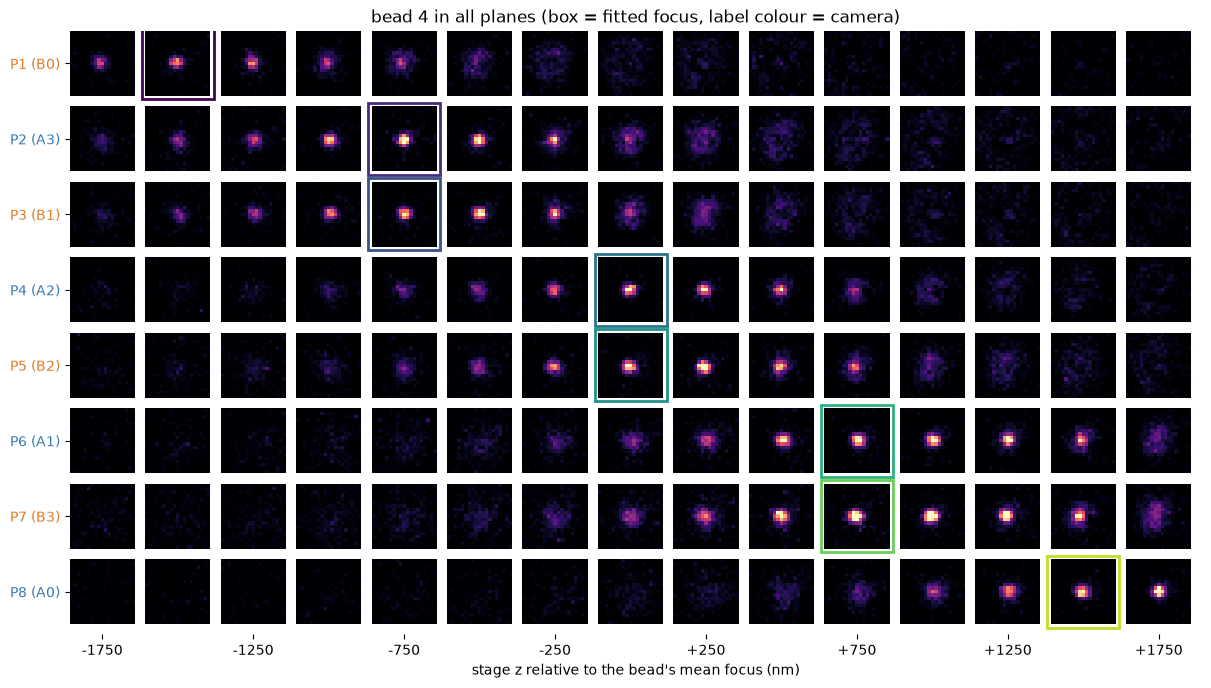

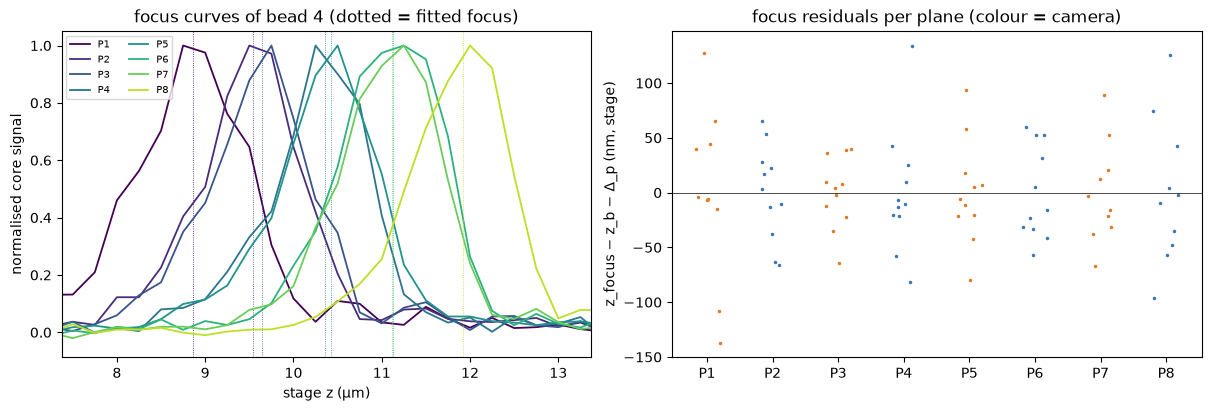

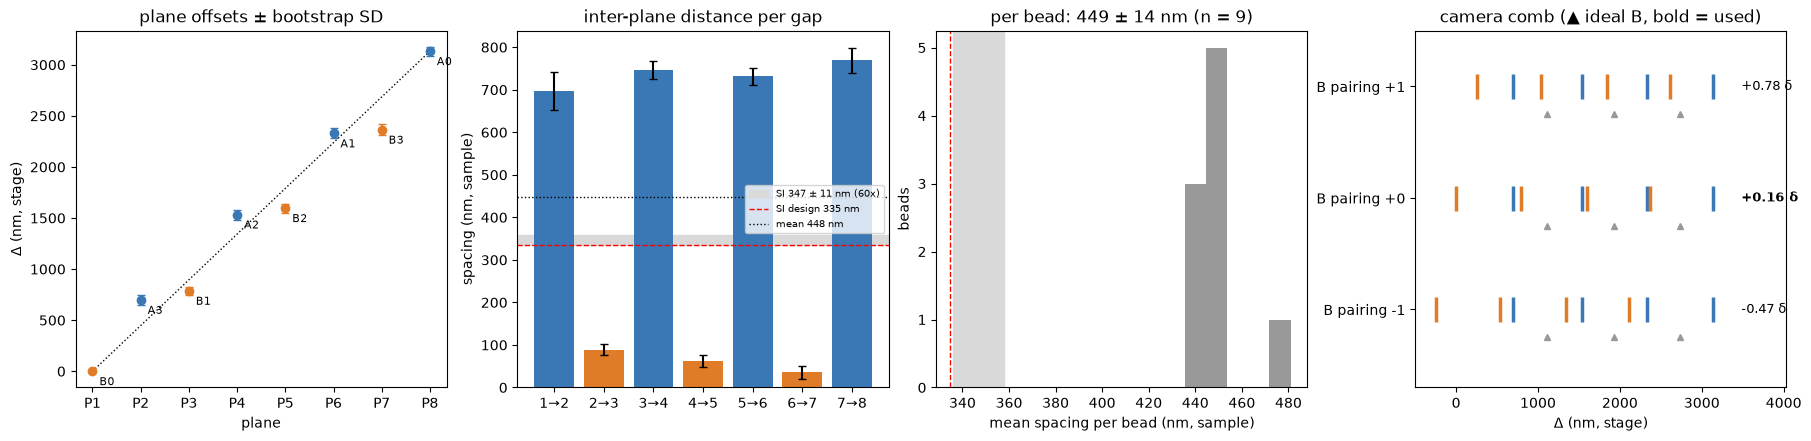

In [6]:
# one bead through focus in all planes
b_show = int(np.nanargmax(np.isfinite(zf).sum(1) + 1e-3 * np.nan_to_num(np.nanmin(snr, 1))))
CROP, GAP, NCOL = BORDER, 3, 15
z_cols = z_bead[b_show] + delta.mean() + STEP * (np.arange(NCOL) - NCOL // 2)
tile = 2 * CROP + 1
mosaic = np.full((P * (tile + GAP), NCOL * (tile + GAP)), np.nan); focus_col = {}
for r, j in enumerate(order):
    if not np.isfinite(pos_mip[b_show, j, 0]):
        continue
    x, y = np.rint(pos_mip[b_show, j]).astype(int); zs = Z[panels[j]["stream"]]
    for c, zc in enumerate(z_cols):
        k = int(np.argmin(np.abs(zs - zc)))
        if abs(zs[k] - zc) <= STEP / 2:
            mosaic[r * (tile + GAP):r * (tile + GAP) + tile, c * (tile + GAP):c * (tile + GAP) + tile] = stacks[j][k, y - CROP:y + CROP + 1, x - CROP:x + CROP + 1]
    if np.isfinite(zf[b_show, j]):
        focus_col[r] = int(np.argmin(np.abs(z_cols - zf[b_show, j])))
fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
cmap = plt.cm.magma.copy(); cmap.set_bad("white")
ax.imshow(mosaic - np.nanmedian(mosaic), cmap=cmap, vmin=0, vmax=np.nanpercentile(mosaic - np.nanmedian(mosaic), 99.9))
for r, c in focus_col.items():
    ax.add_patch(Rectangle((c * (tile + GAP) - 1.5, r * (tile + GAP) - 1.5), tile + 2, tile + 2, fill=False, ec=PCOL[order[r]], lw=2))
ax.set_yticks([r * (tile + GAP) + CROP for r in range(P)]); ax.set_yticklabels([f"{NAME[j]} ({IDS[j]})" for j in order])
for t, j in zip(ax.get_yticklabels(), order):
    t.set_color(CAM_COLOR[STREAM[j]])
ax.set_xticks([c * (tile + GAP) + CROP for c in range(0, NCOL, 2)])
ax.set_xticklabels([f"{1e3 * (zz - z_cols[NCOL // 2]):+.0f}" for zz in z_cols[::2]])
ax.set_xlabel("stage z relative to the bead's mean focus (nm)")
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title(f"bead {b_show} in all planes (box = fitted focus, label colour = camera)")
save(fig, "04a_bead_through_focus.png")

# focus curves and fit quality
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax = axes[0]
for j in order:
    if b_show in curves[j]:
        c = curves[j][b_show]
        ax.plot(Z[STREAM[j]], c / np.nanmax(c), color=PCOL[j], lw=1.3, label=NAME[j])
        if np.isfinite(zf[b_show, j]):
            ax.axvline(zf[b_show, j], color=PCOL[j], lw=0.6, ls=":")
zc = np.nanmean(zf[b_show]); ax.set_xlim(zc - 3, zc + 3)
ax.set(xlabel="stage z (µm)", ylabel="normalised core signal", title=f"focus curves of bead {b_show} (dotted = fitted focus)")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
for j in order:
    ax.plot(np.full(np.isfinite(resid[:, j]).sum(), list(order).index(j) + 1) + np.random.default_rng(j).uniform(-0.2, 0.2, np.isfinite(resid[:, j]).sum()),
            1e3 * resid[np.isfinite(resid[:, j]), j], ".", ms=3, color=CAM_COLOR[STREAM[j]])
ax.axhline(0, color="k", lw=0.5)
ax.set(xticks=range(1, P + 1), xticklabels=[NAME[j] for j in order], ylabel="z_focus − z_b − Δ_p (nm, stage)",
       title="focus residuals per plane (colour = camera)")
save(fig, "04b_focus_curves.png")

# Δ, spacing vs SI and design, camera comb
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3), layout="constrained")
ax = axes[0]; x = np.arange(1, P + 1)
for xi, j in zip(x, order):
    ax.errorbar(xi, 1e3 * delta[j], yerr=1e3 * boot[:, j].std(), fmt="o", color=CAM_COLOR[STREAM[j]], capsize=3)
    ax.annotate(IDS[j], (xi, 1e3 * delta[j]), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.plot(x, 1e3 * gaps.mean() * (x - 1), "k:", lw=1)
ax.set(xlabel="plane", xticks=x, xticklabels=[f"P{i}" for i in x], ylabel="Δ (nm, stage)", title="plane offsets ± bootstrap SD")
ax = axes[1]
ax.bar(np.arange(P - 1), 1e3 * AXIAL_SCALE * gaps, yerr=1e3 * AXIAL_SCALE * gaps_sd, capsize=3,
       color=[CAM_COLOR[STREAM[order[r + 1]]] for r in range(P - 1)])
ax.axhspan(1e3 * (DZ_PAPER - DZ_PAPER_SD), 1e3 * (DZ_PAPER + DZ_PAPER_SD), color="0.85", zorder=0, label="SI 347 ± 11 nm (60x)")
ax.axhline(1e3 * DZ_DESIGN, color="r", ls="--", lw=1, label=f"SI design {1e3 * DZ_DESIGN:.0f} nm")
ax.axhline(1e3 * AXIAL_SCALE * gaps.mean(), color="k", ls=":", lw=1, label=f"mean {1e3 * AXIAL_SCALE * gaps.mean():.0f} nm")
ax.set(xticks=range(P - 1), xticklabels=[f"{r + 1}→{r + 2}" for r in range(P - 1)], ylabel="spacing (nm, sample)",
       title="inter-plane distance per gap"); ax.legend(fontsize=7)
ax = axes[2]
ax.hist(1e3 * AXIAL_SCALE * per_bead, bins=max(5, len(per_bead) // 3), color="0.6")
ax.axvspan(1e3 * (DZ_PAPER - DZ_PAPER_SD), 1e3 * (DZ_PAPER + DZ_PAPER_SD), color="0.85", zorder=0)
ax.axvline(1e3 * DZ_DESIGN, color="r", ls="--", lw=1)
ax.set(xlabel="mean spacing per bead (nm, sample)", ylabel="beads",
       title=f"per bead: {1e3 * AXIAL_SCALE * per_bead.mean():.0f} ± {1e3 * AXIAL_SCALE * per_bead.std(ddof=1):.0f} nm (n = {len(per_bead)})")
ax = axes[3]
dA, dB = np.sort(delta[STREAM == "A"]), np.sort(delta[STREAM == "B"])
for row, s in enumerate(sorted(comb)):
    ax.plot(1e3 * dA, np.full(len(dA), row), "|", color=CAM_COLOR["A"], ms=18, mew=2.5)
    ax.plot(1e3 * (dB + (s - B_SHIFT) * STEP), np.full(len(dB), row), "|", color=CAM_COLOR["B"], ms=18, mew=2.5)
    ax.plot(1e3 * (dA[:-1] + dA[1:]) / 2, np.full(len(dA) - 1, row - 0.25), "^", color="0.6", ms=5)
    ax.text(1e3 * (delta.max() + 0.35), row, f"{comb[s]['offset_delta']:+.2f} δ", va="center", fontsize=9,
            weight="bold" if s == B_SHIFT else "normal")
ax.set(yticks=range(len(comb)), yticklabels=[f"B pairing {s:+d}" for s in sorted(comb)], xlabel="Δ (nm, stage)",
       ylim=(-0.7, len(comb) - 0.5), title="camera comb (▲ ideal B, bold = used)")
ax.set_xlim(1e3 * (delta.min() - 0.5), 1e3 * (delta.max() + 0.9))
save(fig, "04c_plane_spacing.png")

## 5. Extension — focal-plane tilt (not in the paper)
Same fit with an in-panel focus gradient per plane, $z_\text{focus} = z_b + \Delta_p + g_{x,p}x + g_{y,p}y$ (x, y from the panel
centre, Σg = 0 since a common gradient is absorbed by the bead depths). Its Δ_p is the focus at the panel centre. It is
exported as `delta_z_tilt_corrected_um` and used as `delta_z_um` only if `use_tilt_corrected_delta = True`.

axial residual RMS 50.2 nm without tilt terms, 45.7 nm with; max |Δ_tilt − Δ| = 6 nm


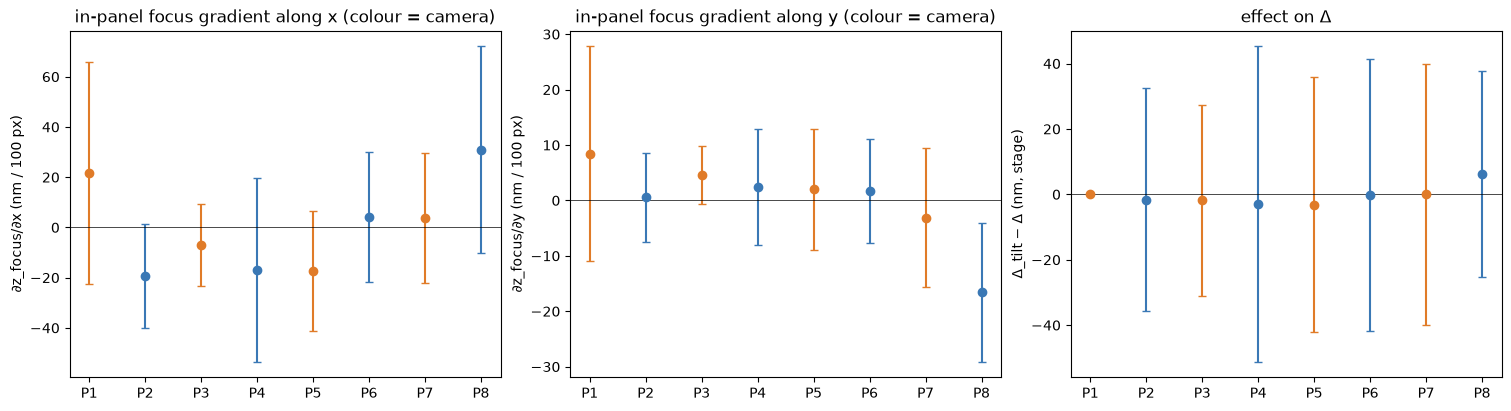

In [7]:
ob, op = np.nonzero(np.isfinite(zf) & np.isfinite(pos_mip[..., 0]))
args = (ob, op, zf[ob, op], pos_mip[ob, op, 0] - WC / 2, pos_mip[ob, op, 1] - HC / 2, P, int(order[0]))
delta_t, gx, gy, res_t = R.tilt_fit(*args)
res_0 = R.tilt_fit(*args, with_tilt=False)[3]
rng = np.random.default_rng(SEED); beads_obs = np.unique(ob); rows_of = {b: np.flatnonzero(ob == b) for b in beads_obs}
bt = []
for _ in range(N_BOOT):
    pick = rng.choice(beads_obs, len(beads_obs)); rows = np.concatenate([rows_of[b] for b in pick])
    ids_ = np.concatenate([np.full(len(rows_of[b]), k) for k, b in enumerate(pick)])
    d_, gx_, gy_, _ = R.tilt_fit(ids_, op[rows], zf[ob[rows], op[rows]], args[3][rows], args[4][rows], P, int(order[0]))
    bt.append(np.r_[d_, gx_, gy_])
bt = np.array(bt); delta_t_sd, gx_sd, gy_sd = bt[:, :P].std(0), bt[:, P:2 * P].std(0), bt[:, 2 * P:].std(0)
print(f"axial residual RMS {1e3 * np.sqrt(np.mean(res_0 ** 2)):.1f} nm without tilt terms, {1e3 * np.sqrt(np.mean(res_t ** 2)):.1f} nm with; "
      f"max |Δ_tilt − Δ| = {1e3 * np.abs(delta_t - delta).max():.0f} nm")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, g, gsd, lab in ((axes[0], gx, gx_sd, "x"), (axes[1], gy, gy_sd, "y")):
    for r, j in enumerate(order):
        ax.errorbar(r + 1, 1e5 * g[j], yerr=1e5 * gsd[j], fmt="o", color=CAM_COLOR[STREAM[j]], capsize=3)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xticks=range(1, P + 1), xticklabels=[NAME[j] for j in order], ylabel=f"∂z_focus/∂{lab} (nm / 100 px)",
           title=f"in-panel focus gradient along {lab} (colour = camera)")
ax = axes[2]
for r, j in enumerate(order):
    ax.errorbar(r + 1, 1e3 * (delta_t[j] - delta[j]), yerr=1e3 * delta_t_sd[j], fmt="o", color=CAM_COLOR[STREAM[j]], capsize=3)
ax.axhline(0, color="k", lw=0.5)
ax.set(xticks=range(1, P + 1), xticklabels=[NAME[j] for j in order], ylabel="Δ_tilt − Δ (nm, stage)", title="effect on Δ")
save(fig, "05_tilt_extension.png")
delta_used = delta_t if USE_TILT_DELTA else delta
delta_used_sd = delta_t_sd if USE_TILT_DELTA else boot.std(0)

## 6. Bead positions at focus
Each bead is localised (2D Gaussian) in every frame within ± `lateral_window_um` of its focus in each plane; a weighted line
x(z), y(z) gives the position at focus. **Extension (off):** a slope common to all planes is a lateral stage drift during the
scan; since every plane sees a bead at a different stage z, the drift adds slope × Δ_p to the affine translations, which does
not exist in a simultaneous acquisition. `correct_common_slope = True` removes it; it would be wrong if the slope were a real
(non-telecentric) property of the optics, which the design excludes (SI §6.1, §6.3). The size of the effect is printed.

common slope: x -42.6, y -27.5 nm per µm stage z -> ≈ 67 nm on the outer planes (not corrected: absorbed in the affine translations)


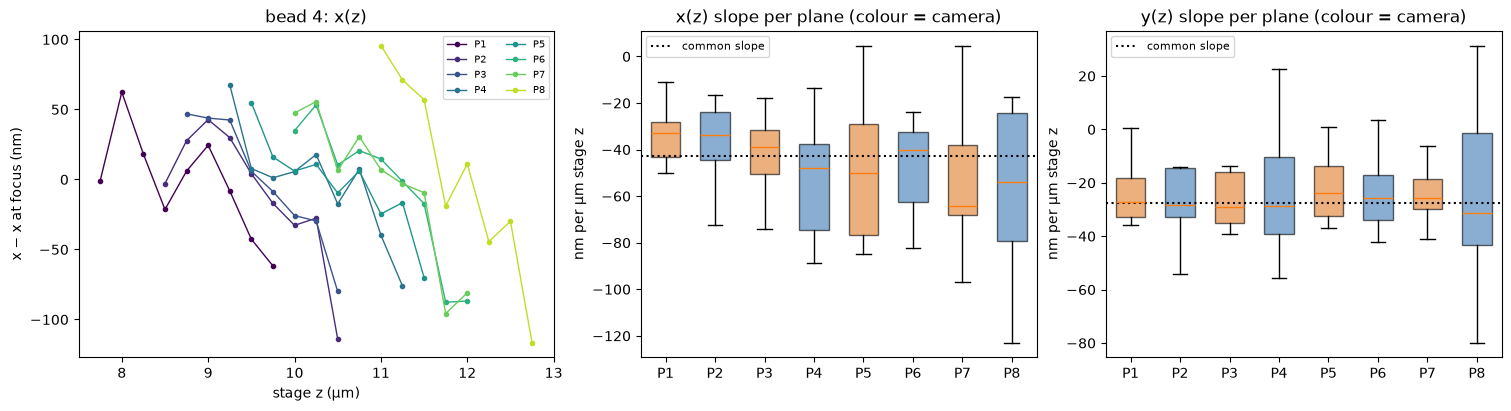

In [8]:
pos_focus = np.full((NB, P, 2), np.nan); pos_sd = np.full_like(pos_focus, np.nan); slope = np.full_like(pos_focus, np.nan); traces = {}
for j, q in enumerate(panels):
    pos_focus[:, j], pos_sd[:, j], slope[:, j], traces[j] = R.positions_at_focus(
        stacks[j], Z[q["stream"]], zf[:, j], pos_mip[:, j], LATERAL_UM, ROI, GAUSS_SIGMA0_UM / PIXEL_UM, LM_ITER, LATERAL_MIN_FRAMES)
pos_corr, common_slope = R.common_slope_correction(pos_focus, slope, zf)
pos_reg = pos_corr if CORRECT_COMMON_SLOPE else pos_focus
NM = 1e3 * PIXEL_UM
eff = NM * np.abs(common_slope).max() * (delta.max() - delta.min()) / 2
print(f"common slope: x {NM * common_slope[0]:+.1f}, y {NM * common_slope[1]:+.1f} nm per µm stage z -> ≈ {eff:.0f} nm on the outer "
      f"planes ({'corrected' if CORRECT_COMMON_SLOPE else 'not corrected: absorbed in the affine translations'})")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax = axes[0]
for j in order:
    if b_show in traces[j]:
        zz, xy = traces[j][b_show]
        ax.plot(zz, NM * (xy[:, 0] - pos_focus[b_show, j, 0]), "o-", ms=3, lw=1, color=PCOL[j], label=NAME[j])
ax.set(xlabel="stage z (µm)", ylabel="x − x at focus (nm)", title=f"bead {b_show}: x(z)"); ax.legend(fontsize=7, ncol=2)
for a, ax in zip((0, 1), axes[1:]):
    data = [NM * slope[np.isfinite(slope[:, j, a]), j, a] for j in order]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6)
    for patch, j in zip(bp["boxes"], order):
        patch.set_facecolor(CAM_COLOR[STREAM[j]]); patch.set_alpha(0.6)
    ax.axhline(NM * common_slope[a], color="k", ls=":", label="common slope")
    ax.set(xticks=range(1, P + 1), xticklabels=[NAME[j] for j in order], ylabel="nm per µm stage z",
           title=f"{'xy'[a]}(z) slope per plane (colour = camera)"); ax.legend(fontsize=8)
save(fig, "06_lateral.png")

## 7. Affine registration onto the reference plane (SI §6.4, Fig. S16)
Every plane gets an affine map plane → reference fitted on the bead positions at focus (clipping at `affine_clip_sigma`). The
reference plane is a declared choice (the SI registers pairs of channels; one reference is equivalent by composition). Bars:
**leave-one-out** error (a bead not used in the fit); ◆ 2nd-order polynomial (diagnostic: if not clearly lower, the affine is
enough); dashed: localisation floor. Arrows: residual per bead.

reference P5 (B2)
plane panel   n  rej  scale x/y        rot (°)   shift (px)        LOO (nm)  poly2  floor
P1    B0     10   0  0.9996/0.9998   +0.033  (-24.76,  +1.61)     10.9   21.6    4.8
P2    A3     10   1  0.9993/0.9998   +0.135  ( -8.38,  +2.55)     11.0  1598.7    4.1
P3    B1      9   2  1.0002/1.0000   +0.037  ( +3.58,  +1.53)     14.9  372.3    3.4
P4    A2     10   1  1.0004/1.0001   +0.117  ( +0.63,  +2.87)      8.0   44.1    3.9
P6    A1     11   0  1.0000/1.0002   +0.081  ( +2.88,  +2.17)     17.9   39.5    4.0
P7    B3     10   0  0.9998/1.0003   -0.002  ( +4.26,  +1.41)     18.5   34.8    3.9
P8    A0     10   0  1.0001/1.0004   +0.092  ( +7.34,  +2.86)     15.1  50212.3    4.1


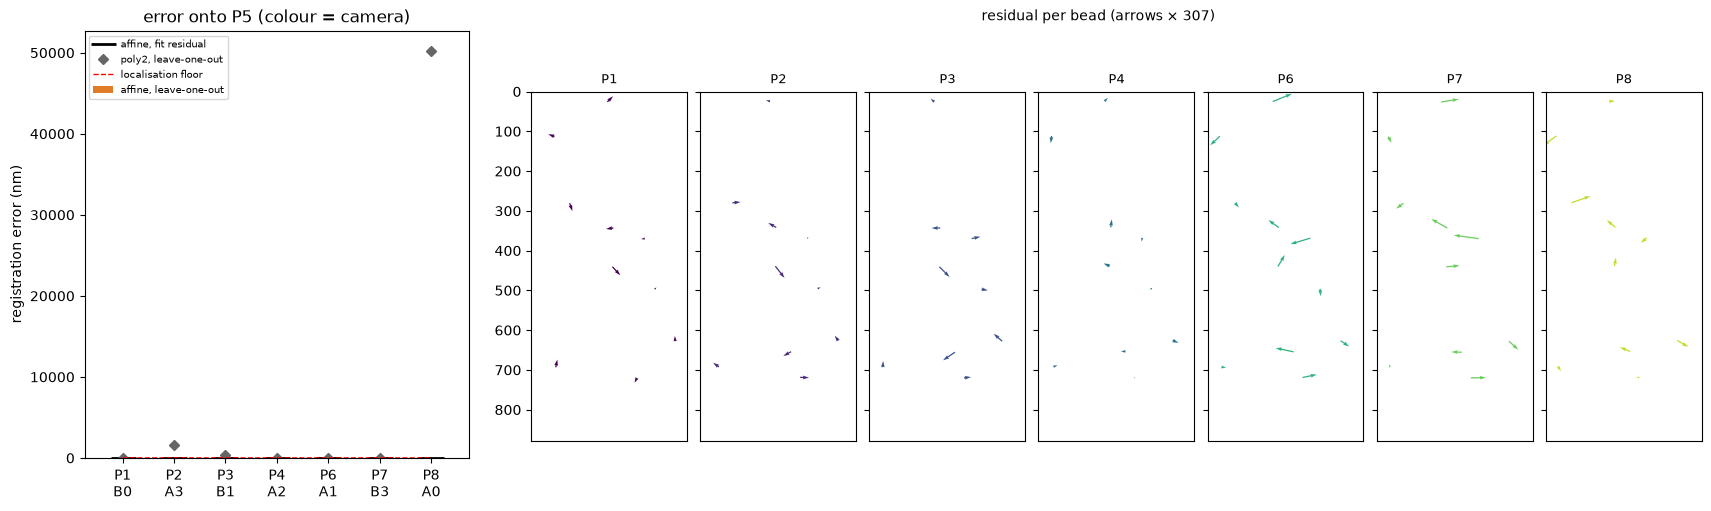

In [9]:
ref_j = next(j for j in range(P) if NAME[j] == REFERENCE_PLANE)
aff_to_ref, rs = R.register_planes(pos_reg, ref_j, AFFINE_CLIP, AFFINE_ITER, pos_sd)
oth = [j for j in order if j != ref_j]
print(f"reference {REFERENCE_PLANE} ({IDS[ref_j]})")
print("plane panel   n  rej  scale x/y        rot (°)   shift (px)        LOO (nm)  poly2  floor")
for j in oth:
    s_, M = rs[j], aff_to_ref[j]
    print(f"{NAME[j]:5s} {IDS[j]:5s} {s_['n']:3d} {s_['n_rejected']:3d}  {s_['scale_x']:.4f}/{s_['scale_y']:.4f}  {s_['rotation_deg']:+7.3f}  "
          f"({M[0, 2]:+6.2f}, {M[1, 2]:+6.2f})   {NM * s_['loo_rms_px']:6.1f}  {NM * s_['loo_rms_poly2_px']:5.1f}  {NM * s_['floor_px']:5.1f}")
    if s_["det"] < 0:
        warn(f"{NAME[j]}: negative affine determinant (still mirrored relative to the reference)")
poly2 = [NAME[j] for j in oth if rs[j]["loo_rms_poly2_px"] < WARN_POLY2 * rs[j]["loo_rms_px"]]
if poly2:
    warn(f"2nd-order polynomial beats the affine by > {100 * (1 - WARN_POLY2):.0f} % (LOO) for {poly2}: field distortion")

fig = plt.figure(figsize=(17, 5), layout="constrained")
sub = fig.subfigures(1, 2, width_ratios=[1, 2.6])
ax = sub[0].subplots(); xs = np.arange(len(oth))
ax.bar(xs, [NM * rs[j]["loo_rms_px"] for j in oth], color=[CAM_COLOR[STREAM[j]] for j in oth], label="affine, leave-one-out")
ax.plot(xs, [NM * rs[j]["rms_px"] for j in oth], "_", color="k", ms=18, mew=2, label="affine, fit residual")
ax.plot(xs, [NM * rs[j]["loo_rms_poly2_px"] for j in oth], "D", color="0.4", ms=5, label="poly2, leave-one-out")
ax.plot(xs, [NM * rs[j]["floor_px"] for j in oth], "--", color="r", lw=1, label="localisation floor")
ax.set(xticks=xs, xticklabels=[f"{NAME[j]}\n{IDS[j]}" for j in oth], ylabel="registration error (nm)",
       title=f"error onto {REFERENCE_PLANE} (colour = camera)"); ax.legend(fontsize=7)
axs = sub[1].subplots(1, len(oth), sharey=True)
allr = np.concatenate([np.hypot(*rs[j]["resid"].T) for j in oth]); scale = 20.0 / max(np.median(allr), 1e-3)
for ax, j in zip(axs, oth):
    q_ = ax.quiver(rs[j]["src"][:, 0], rs[j]["src"][:, 1], rs[j]["resid"][:, 0] * scale, rs[j]["resid"][:, 1] * scale,
                   angles="xy", scale_units="xy", scale=1, width=0.008, color=PCOL[j])
    ax.set_xlim(0, WC); ax.set_ylim(HC, 0); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_title(NAME[j], fontsize=9)
ref_len = max(float(np.round(NM * np.percentile(allr, 90))), 1.0)
axs[0].quiverkey(q_, 0.3, 0.03, ref_len / NM * scale, f"{ref_len:.0f} nm", labelpos="E", coordinates="axes")
sub[1].suptitle(f"residual per bead (arrows × {scale:.0f})", fontsize=10)
save(fig, "07_registration.png")

## 8. Channel transmission (SI §6.4)
All planes record the same bead emission at the same frame, so the ratio of a bead's integrated signal between planes at a
common frame is the ratio of channel transmissions, independent of bleaching and bead brightness. Frames around each bead's mean
focus; disc of `transmission_radius_um` minus the annulus background (offset-subtracted data). The disc must contain the
defocused images of the outer planes: the right panel must be flat at the chosen radius. This is the fluorescence-channel
transmission at the bead emission wavelength (used for SOFI in the SI); for phase, the SI corrects transmission with bright-field
images (per-acquisition flat field, notebook 03/04).

transmission from 9 beads (all planes, ≥ 2.5 µm from the edges):
  P1 1.099±0.040  P2 1.133±0.029  P3 1.049±0.052  P4 0.851±0.018  P5 0.943±0.051  P6 0.876±0.070  P7 1.135±0.039  P8 0.914±0.037


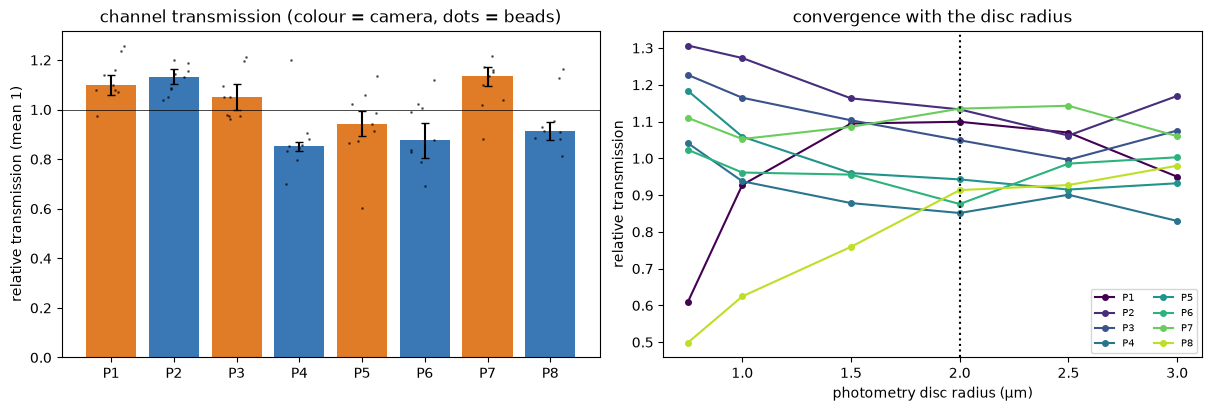

In [10]:
kc = np.rint((np.nanmean(zf, 1) - Z["A"][0]) / STEP)
kc = np.where(np.isfinite(kc), kc, -10**6).astype(int)
HF = int(round(TRANS_HALF_UM / STEP))
trans, trans_sd, per_bead_T, used_T = R.channel_transmission(stacks, pos_reg, kc, HF, u(TRANS_RADIUS_UM), u(TRANS_BG_UM), N_BOOT, SEED)
conv = np.array([R.channel_transmission(stacks, pos_reg, kc, HF, u(r_), u(TRANS_BG_UM), 1, SEED)[0] for r_ in TRANS_RADII_CHECK_UM])
print(f"transmission from {len(used_T)} beads (all planes, ≥ {TRANS_RADIUS_UM + TRANS_BG_UM} µm from the edges):")
print("  " + "  ".join(f"{NAME[j]} {trans[j]:.3f}±{trans_sd[j]:.3f}" for j in order))
if len(used_T) < 5:
    warn(f"transmission from only {len(used_T)} beads")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax = axes[0]
ax.bar(range(P), [trans[j] for j in order], yerr=[trans_sd[j] for j in order], capsize=3, color=[CAM_COLOR[STREAM[j]] for j in order])
for k_, j in enumerate(order):
    ax.plot(np.full(len(per_bead_T), k_) + np.random.default_rng(k_).uniform(-0.25, 0.25, len(per_bead_T)),
            per_bead_T[:, j] / np.median(per_bead_T, 0).mean(), ".", color="k", ms=2, alpha=0.5)
ax.axhline(1, color="k", lw=0.5)
ax.set(xticks=range(P), xticklabels=[NAME[j] for j in order], ylabel="relative transmission (mean 1)",
       title="channel transmission (colour = camera, dots = beads)")
ax = axes[1]
for j in order:
    ax.plot(TRANS_RADII_CHECK_UM, conv[:, j], "o-", color=PCOL[j], label=NAME[j], ms=4)
ax.axvline(TRANS_RADIUS_UM, color="k", ls=":")
ax.set(xlabel="photometry disc radius (µm)", ylabel="relative transmission", title="convergence with the disc radius")
ax.legend(fontsize=7, ncol=2)
save(fig, "08_transmission.png")

## 9. Overlay check
Bead projections warped onto the reference with the fitted affine and bilinear interpolation (`geometry.warp`, SI §6.4).
Left: NCC on bead pixels with the coarse shift only (○) and after the affine (●). Right: outer planes, magenta = reference,
green = warped plane, white = registered.

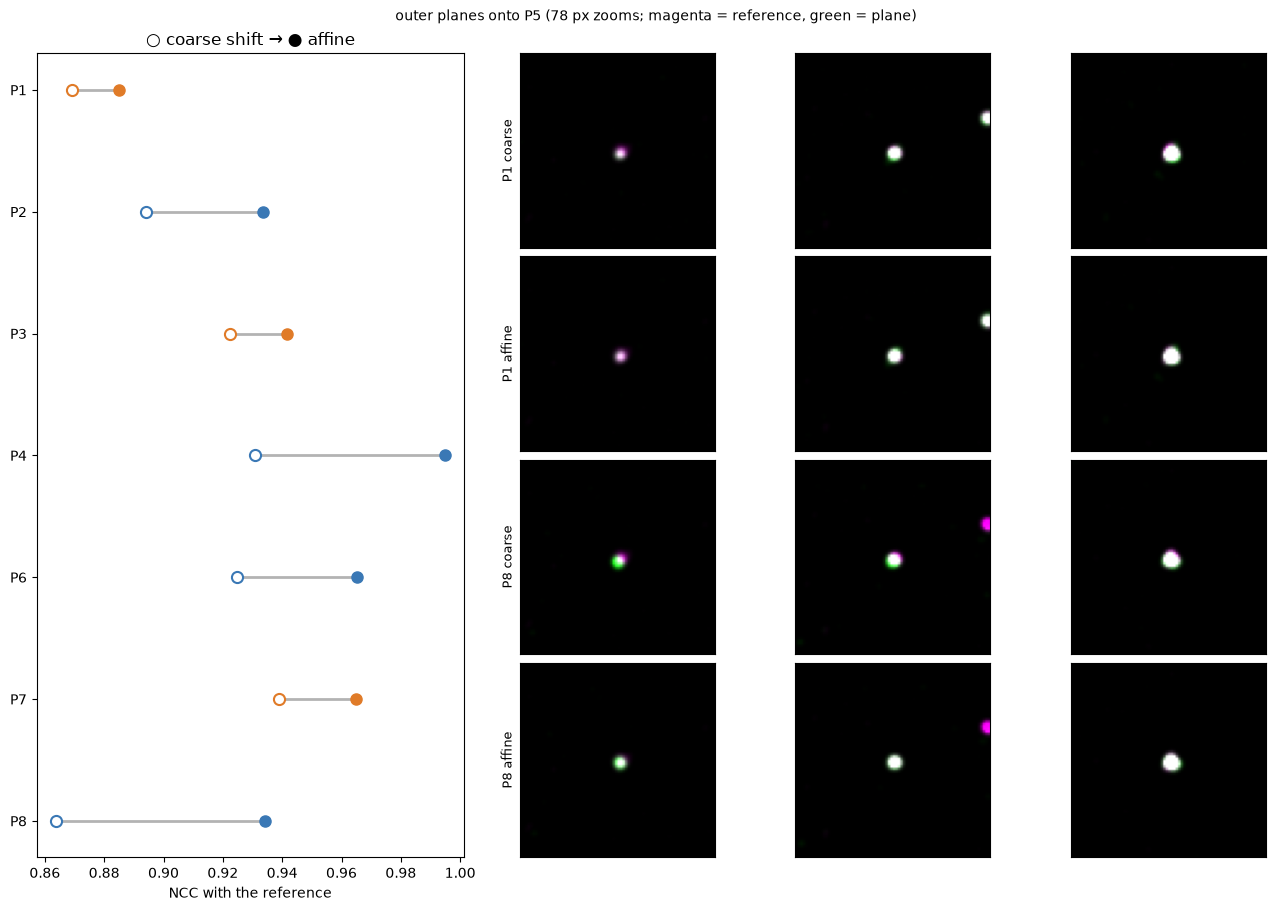

In [11]:
aff_from_ref = {j: R.invert_affine(aff_to_ref[j]) for j in range(P)}
ref_img = mips[IDS[ref_j]]; NB_PX = u(NCC_BORDER_UM)
coarse = {j: ndimage.shift(mips[IDS[j]], -np.rint(shifts[IDS[j]] - shifts[IDS[ref_j]])[::-1], order=0) for j in oth}
warped = {j: geometry.warp(mips[IDS[j]], aff_from_ref[j]) for j in oth}
ncc = {j: (R.ncc(ref_img, coarse[j], NCC_THR, NB_PX), R.ncc(ref_img, warped[j], NCC_THR, NB_PX)) for j in oth}
outer = [order[0], order[-1]]
refp = pos_reg[np.isfinite(pos_reg[:, ref_j, 0]), ref_j]
HALF = max(u(4.4), 10)
zooms = []
for cy, cx in [(HC // 4, WC // 4), (HC // 2, WC // 2), (3 * HC // 4, 3 * WC // 4)]:
    k = int(np.argmin(np.hypot(refp[:, 0] - cx, refp[:, 1] - cy)))
    zooms.append((int(np.clip(refp[k, 1], HALF, HC - HALF)), int(np.clip(refp[k, 0], HALF, WC - HALF))))
mos = [["N"] + [f"z{r}{k}" for k in range(len(zooms))] for r in range(2 * len(outer))]
fig, axd = plt.subplot_mosaic(mos, figsize=(13, 9), layout="constrained", gridspec_kw={"width_ratios": [1.6] + [1] * len(zooms)})
ax = axd["N"]
for i, j in enumerate(oth):
    ax.plot(ncc[j], [i, i], color="0.7", lw=2, zorder=0)
    ax.plot(ncc[j][0], i, "o", mfc="white", mec=CAM_COLOR[STREAM[j]], mew=1.5, ms=8)
    ax.plot(ncc[j][1], i, "o", color=CAM_COLOR[STREAM[j]], ms=8)
ax.set(yticks=range(len(oth)), yticklabels=[NAME[j] for j in oth], xlabel="NCC with the reference", title="○ coarse shift → ● affine")
ax.invert_yaxis()
for i, j in enumerate(outer):
    for k, (cy, cx) in enumerate(zooms):
        sl = (slice(cy - HALF, cy + HALF), slice(cx - HALF, cx + HALF))
        for row, img, lab in ((2 * i, coarse[j], "coarse"), (2 * i + 1, warped[j], "affine")):
            a_ = axd[f"z{row}{k}"]; a_.imshow(overlay(ref_img, img, 0.7)[sl]); a_.set_xticks([]); a_.set_yticks([])
            if k == 0:
                a_.set_ylabel(f"{NAME[j]} {lab}", fontsize=9)
fig.suptitle(f"outer planes onto {REFERENCE_PLANE} ({2 * HALF} px zooms; magenta = reference, green = plane)", fontsize=10)
save(fig, "09_overlay.png")

## 10. Summary and export
`calibration.json` follows the contract of `docs/DESIGN.md`: per plane the stream, raw window, orientation, Δ in sample space
(`delta_z_um`) and stage space (`delta_z_stage_um`), the affine reference → plane (`affine_from_reference`, what
`geometry.warp` needs) and the channel transmission. Δ is relative to P1 (lowest stage z).

In [12]:
S = AXIAL_SCALE
gap_u = np.diff(delta_used[order])
summary = [f"beads {NB}; camera B orientation '{orient_B}'; camera sequence {seq}",
           f"plane spacing (sample) {1e3 * S * gap_u.mean():.0f} nm, per bead {1e3 * S * per_bead.mean():.0f} ± {1e3 * S * per_bead.std(ddof=1):.0f} nm"
           f" (n = {len(per_bead)}) | SI {1e3 * DZ_PAPER:.0f} ± {1e3 * DZ_PAPER_SD:.0f} nm | design {1e3 * DZ_DESIGN:.0f} nm",
           f"axial scale n_sample/n_imm = {N_SAMPLE}/{N_IMM} = {S:.3f} (paraxial)",
           f"camera-B comb offset {off_now:+.2f} δ (instrument pairing {B_SHIFT}; ±1 = designed interleave)",
           f"registration LOO error: median {NM * np.median([rs[j]['loo_rms_px'] for j in oth]):.0f} nm, worst "
           f"{NM * max(rs[j]['loo_rms_px'] for j in oth):.0f} nm onto {REFERENCE_PLANE}",
           f"transmission range {np.nanmin(trans):.3f} – {np.nanmax(trans):.3f} ({len(used_T)} beads)",
           f"extensions: tilt Δ {'USED' if USE_TILT_DELTA else 'reported only'}, common-slope correction "
           f"{'ON' if CORRECT_COMMON_SLOPE else 'off'}", f"{len(WARNINGS)} warning(s)"]
print("\n".join(summary) + "".join("\n  - " + textwrap.fill(w, 110, subsequent_indent="    ") for w in WARNINGS))

L = lambda a: np.round(np.asarray(a, float), 6).tolist()
planes_out = []
for j in order:
    q, w = panels[j], panels[j]["window_raw"]
    e = {"plane": NAME[j], "stream": q["stream"], "panel_id": q["id"], "window_raw": dict(w), "orientation": q["orientation"],
         "delta_z_um": float(S * delta_used[j]), "delta_z_stage_um": float(delta_used[j]), "delta_z_sd_um": float(S * delta_used_sd[j]),
         "delta_z_paper_stage_um": float(delta[j]), "delta_z_tilt_corrected_um": float(S * delta_t[j]),
         "affine_from_reference": L(aff_from_ref[j]), "affine_to_reference": L(aff_to_ref[j]),
         "transmission": float(trans[j]), "transmission_sd": float(trans_sd[j])}
    if j in rs:
        e["registration"] = {"n": rs[j]["n"], "n_rejected": rs[j]["n_rejected"], "rms_nm": NM * rs[j]["rms_px"],
                             "loo_rms_nm": NM * rs[j]["loo_rms_px"], "loo_rms_poly2_nm": NM * rs[j]["loo_rms_poly2_px"],
                             "floor_nm": NM * rs[j]["floor_px"], **{k: rs[j][k] for k in ("scale_x", "scale_y", "rotation_deg", "shear", "det")},
                             "ncc_coarse": ncc[j][0], "ncc_affine": ncc[j][1]}
    planes_out.append(e)
spacing = {"mean": float(S * gap_u.mean()), "sd": float(S * per_bead.std(ddof=1)) if len(per_bead) > 1 else None,
           "sd_definition": "SD over beads of (z_P8 − z_P1)/7, as SI §6.2", "per_gap": L(S * gap_u), "per_gap_sd": L(S * gaps_sd),
           "sd_between_gaps": float(S * gap_u.std(ddof=1)), "per_bead_mean": float(S * per_bead.mean()), "n_beads": int(len(per_bead)),
           "stage": {"mean": float(gap_u.mean()), "per_gap": L(gap_u), "per_bead_mean": float(per_bead.mean()),
                     "per_bead_sd": float(per_bead.std(ddof=1)) if len(per_bead) > 1 else None}}
calib = {
    "planes": planes_out, "reference_plane": REFERENCE_PLANE, "plane_order": [NAME[j] for j in order],
    "plane_spacing_um": spacing, "plane_spacing_design_um": DZ_DESIGN, "plane_spacing_paper_um": {"mean": DZ_PAPER, "sd": DZ_PAPER_SD},
    "pixel_um": PIXEL_UM, "objective": OBJECTIVE, "n_sample": N_SAMPLE, "n_immersion": N_IMM, "axial_scale": S, "step_um": STEP,
    "source_file": str(DATA_FILE.name), "n_beads": int(NB), "stream_B_orientation": orient_B,
    "camera_B_comb": {"assumed_pairing_shift": B_SHIFT, "offset_in_delta": {str(k): v["offset_delta"] for k, v in comb.items()},
                      "delta_unit_um": d_unit, "sequence": seq},
    "common_xy_slope_nm_per_um": L(NM * common_slope),
    "focal_plane_tilt": {"gx_nm_per_px": {NAME[j]: 1e3 * gx[j] for j in range(P)}, "gy_nm_per_px": {NAME[j]: 1e3 * gy[j] for j in range(P)},
                         "status": "extension (not in the SI)"},
    "transmission_note": "fluorescence-channel transmission from the bead scan (SI §6.4, SOFI); bright-field phase uses a flat field",
    "conventions": {"streams": "io.load (instrument file: dat_stream_order / tiff_files)",
                    "panel": "geometry.panel: raw[top:top+h, left:left+w], then orientation ('lr' reverses columns, 'ud' rows)",
                    "coordinates": "(x, y) = (column, row) in the oriented panel, pixel centres at integers",
                    "affine_from_reference": "2x3: [x_plane, y_plane] = M[:, :2] @ [x_ref, y_ref] + M[:, 2] (geometry.warp)",
                    "delta_z_um": "stage z of focus in this plane relative to P1, × axial_scale (sample space); planes in ascending stage z",
                    "plane_spacing_um.mean": "mean gap of consecutive Δ (sample space)"},
    "config": {"correct_common_slope": CORRECT_COMMON_SLOPE, "use_tilt_corrected_delta": USE_TILT_DELTA,
               "stream_b_z_shift_steps": B_SHIFT, "axial_scale": S, "panel_margin_px": PANEL_MARGIN_PX, "step_um": STEP},
    "warnings": WARNINGS,
    # previous notebook-02 keys
    "mean_spacing_um": float(S * gap_u.mean()), "spacings_um": L(S * gap_u), "spacings_sd_um": L(S * gaps_sd),
}
write_json(OUT / "calibration.json", calib, step="01_registration", inputs={"data": DATA_FILE})
np.savez_compressed(OUT / "beads.npz", panel_ids=np.array(IDS), plane_names=np.array([NAME[j] for j in range(P)]),
                    pos_mip=pos_mip, z_focus=z_focus, z_focus_clean=zf, z_bead=z_bead, pos_focus=pos_focus, pos_sd=pos_sd,
                    slope=slope, pos_reg=pos_reg, delta_stage=delta, delta_tilt_stage=delta_t)
print("wrote", OUT / "calibration.json", "and beads.npz")

beads 11; camera B orientation 'lr'; camera sequence BABABABA
plane spacing (sample) 448 nm, per bead 449 ± 14 nm (n = 9) | SI 347 ± 11 nm | design 335 nm
axial scale n_sample/n_imm = 1.33/1.33 = 1.000 (paraxial)
camera-B comb offset +0.16 δ (instrument pairing 0; ±1 = designed interleave)
registration LOO error: median 15 nm, worst 19 nm onto P5
transmission range 0.851 – 1.135 (9 beads)
extensions: tilt Δ reported only, common-slope correction off
2 warning(s)
  - only 11 beads: affine and axial statistics will be weak
  - camera-B comb offset +0.16 δ (design ±1): camera B is off its interleaved position or the frame pairing is
    wrong; pairing shifts consistent with the design: [1] (instrument value: 0)
wrote /Users/quentingresil/Library/CloudStorage/OneDrive-epfl.ch/POSTDOC/data/260928_registration/20260928_134359_GPSBeads_Stock_1-10_Agarpse_2_488nm_zstack_01_registration/calibration.json and beads.npz
